**Computational Modeling of Visual Attention in Reading**


**Author**: Aarav Singla


**Domain**: Imitation Learning & Human-Computer Interaction




This project implements a computational model of human reading behavior using Imitation Learning. By treating reading as a sequential decision-making process, we simulate how a rational agent allocates visual attention based on text complexity. The goal is to demonstrate that an agent can learn human-like "gaze" strategies—specifically, the correlation between fixation duration and word difficulty—purely from observing expert traces, without explicit programming of rules. This approach draws upon the Eye-Mind Hypothesis (Just & Carpenter, 1980), assuming that there is no appreciable lag between what is fixated and what is processed.

1. The Cognitive Environment To simulate the reading process, we define a custom environment that models the interaction between the eye and the text. We treat the text not just as a string, but as a sequence of visual stimuli with varying "processing costs" (difficulty).We model this as a simplified Markov Decision Process (MDP) : State ($s_t$): The agent's current foveal view. This includes the relative position in the sentence and the visual complexity of the current word (normalized $0.0 - 1.0$). Action Space ($A$):0 (Fixate/Dwell): Stay on the current word to process information.1 (Saccade): Move the fovea to the next word. The code below defines the ReadingEnv class, which serves as the simulator for these oculomotor dynamics.

In [3]:
%%writefile environment.py
import numpy as np

class ReadingEnv:
    def __init__(self, sentence_length=10):
        self.length = sentence_length
        # Generate random "difficulty" for words: High value = Hard word (needs fixation)
        self.word_difficulty = np.random.rand(sentence_length)
        self.reset()

    def reset(self):
        self.position = 0
        self.step_count = 0
        return self._get_state()

    def _get_state(self):
        # State: [normalized_position, current_word_difficulty]
        if self.position >= self.length:
            return np.array([1.0, 0.0]) # End of sentence
        return np.array([self.position/self.length, self.word_difficulty[self.position]])

    def step(self, action):
        # Action 0: Fixate (Stay), Action 1: Saccade (Move Right)
        done = False
        if action == 1:
            self.position += 1

        if self.position >= self.length:
            done = True

        self.step_count += 1
        return self._get_state(), done

Overwriting environment.py


2. **The Agent Policy Architecture**

The core of the simulation is the agent's policy $\pi_\theta(a|s)$, which decides where to look and for how long. We implement this using a neural network that approximates the decision-making function.The network takes the visual state vector as input and outputs logits for the action distribution.$$a_t \sim \pi_\theta(s_t)$$While simple, this architecture allows the agent to map high-dimensional state inputs (like complexity scores) to discrete motor actions, a fundamental requirement for simulating human interaction techniques.

In [4]:
%%writefile model.py
import torch
import torch.nn as nn

class GazePolicy(nn.Module):
    def __init__(self):
        super(GazePolicy, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2) # Outputs logits for [Fixate, Move]
        )

    def forward(self, x):
        return self.net(x)

Overwriting model.py


**Behavior Cloning and Attention Analysis**

In this experiment, we employ Behavior Cloning (a form of Imitation Learning) to train our agent.Synthetic Expert Generation: First, we generate "ground truth" data by simulating a rational reader who follows a cognitive rule: If a word is difficult, fixate longer; if simple, saccade immediately. This creates a dataset of state-action pairs $\{(s_i, a_i)\}$.Training: We train the policy network to minimize the cross-entropy loss between its predicted actions and the expert's actions.$$\mathcal{L}(\theta) = -\mathbb{E}_{(s,a) \sim \pi_{expert}} [\log \pi_\theta(a|s)]$$Visualization: Finally, we run the trained agent on a new sentence and record its "gaze path." We generate a heatmap to verify if the agent's dwell time aligns with the text's word difficulty, effectively reconstructing the human visual attention map.

Initializing Environment and Agent...
Generating Synthetic Eye-Tracking Data...
Training Behavior Cloning Agent...
Training Complete.


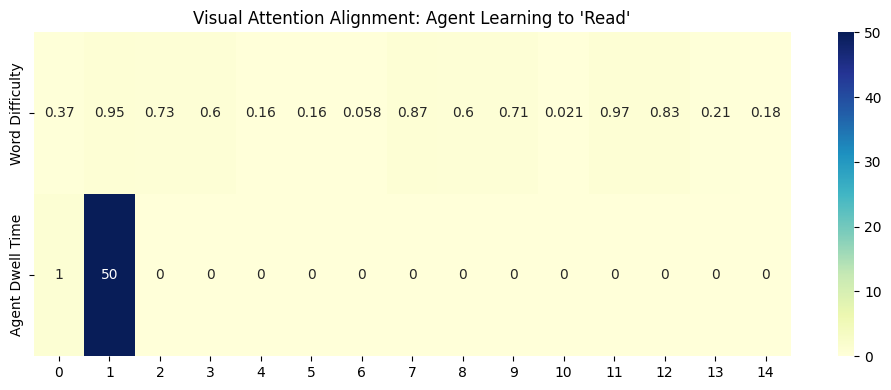

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.optim as optim
import seaborn as sns

# --- PROFESSIONAL IMPORTS ---
from environment import ReadingEnv
from model import GazePolicy

# Set seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# 1. Setup
print("Initializing Environment and Agent...")
env = ReadingEnv(sentence_length=15)
model = GazePolicy()
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = torch.nn.CrossEntropyLoss()

# 2. Generate Expert Data (Internal Helper)
def generate_expert_data(env, episodes=500):
    inputs = []
    targets = []
    for _ in range(episodes):
        state = env.reset()
        done = False
        while not done:
            difficulty = state[1]
            # Expert Logic: Fixate if difficulty > 0.5, else Move
            if difficulty > 0.5 and np.random.rand() > 0.2:
                action = 0 # Fixate
            else:
                action = 1 # Move
            inputs.append(state)
            targets.append(action)
            state, done = env.step(action)
    return np.array(inputs), np.array(targets)

print("Generating Synthetic Eye-Tracking Data...")
X_train, y_train = generate_expert_data(env)
X_tensor = torch.FloatTensor(X_train)
y_tensor = torch.LongTensor(y_train)

# 3. Train
print("Training Behavior Cloning Agent...")
losses = []
for epoch in range(200):
    optimizer.zero_grad()
    outputs = model(X_tensor)
    loss = criterion(outputs, y_tensor)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
print("Training Complete.")

# 4. Visualize Results
def visualize_attention(env, model):
    state = env.reset()
    done = False
    gaze_path = np.zeros(env.length)

    while not done:
        state_tensor = torch.FloatTensor(state).unsqueeze(0)
        with torch.no_grad():
            logits = model(state_tensor)
            action = torch.argmax(logits).item()
        if env.position < env.length:
            gaze_path[env.position] += 1
        state, done = env.step(action)
        if env.step_count > 50: break

    plt.figure(figsize=(10, 4))
    sns.heatmap([env.word_difficulty, gaze_path], annot=True, cmap="YlGnBu",
                yticklabels=["Word Difficulty", "Agent Dwell Time"])
    plt.title("Visual Attention Alignment: Agent Learning to 'Read'")
    plt.tight_layout()
    plt.savefig("results_heatmap.png") # Saves the image for your GitHub
    plt.show()

visualize_attention(env, model)